In [1]:

import pandas as pd

data = {
    "Region": ["Mumbai", "Pune", "Nashik", "Nagpur"],
    "Total_Tickets": [120, 95, 80, 105],
    "Resolved_Tickets": [114, 90, 68, 100]
}

df = pd.DataFrame(data)
df["Resolution_Rate"] = (
    df["Resolved_Tickets"] / df["Total_Tickets"] * 100
).round(2)

display(df)
print("Average resolution rate:", round(df["Resolution_Rate"].mean(), 2), "%")


,Region,Total_Tickets,Resolved_Tickets,Resolution_Rate
0,Mumbai,120,114,95.00
1,Pune,95,90,94.74
2,Nashik,80,68,85.00
3,Nagpur,105,100,95.24


Average resolution rate: 92.5 %


In [2]:

import pandas as pd

data = {
    "Region": ["Mumbai", "Pune", "Nashik", "Nagpur"],
    "Total_Tickets": [120, 95, 80, 105],
    "Resolved_Tickets": [114, 90, 68, 100],
    "SLA_Target": [95, 95, 90, 95]
}

df = pd.DataFrame(data)

df["Resolution_Rate"] = (
    df["Resolved_Tickets"] / df["Total_Tickets"] * 100
).round(2)

df["SLA_Status"] = df.apply(
    lambda row: "Met"
    if row["Resolution_Rate"] >= row["SLA_Target"]
    else "Breached",
    axis=1
)

display(df)

print("\nRegional SLA Summary:")
print("Total Tickets:", df["Total_Tickets"].sum())
print("Resolved Tickets:", df["Resolved_Tickets"].sum())
print("Overall Resolution Rate:",
      round(df["Resolved_Tickets"].sum() /
            df["Total_Tickets"].sum() * 100, 2), "%")
print("Regions with SLA Breach:",
      (df["SLA_Status"] == "Breached").sum())

,Region,Total_Tickets,Resolved_Tickets,SLA_Target,Resolution_Rate,SLA_Status
0,Mumbai,120,114,95,95.00,Met
1,Pune,95,90,95,94.74,Breached
2,Nashik,80,68,90,85.00,Breached
3,Nagpur,105,100,95,95.24,Met



Regional SLA Summary:
Total Tickets: 400
Resolved Tickets: 372
Overall Resolution Rate: 93.0 %
Regions with SLA Breach: 2


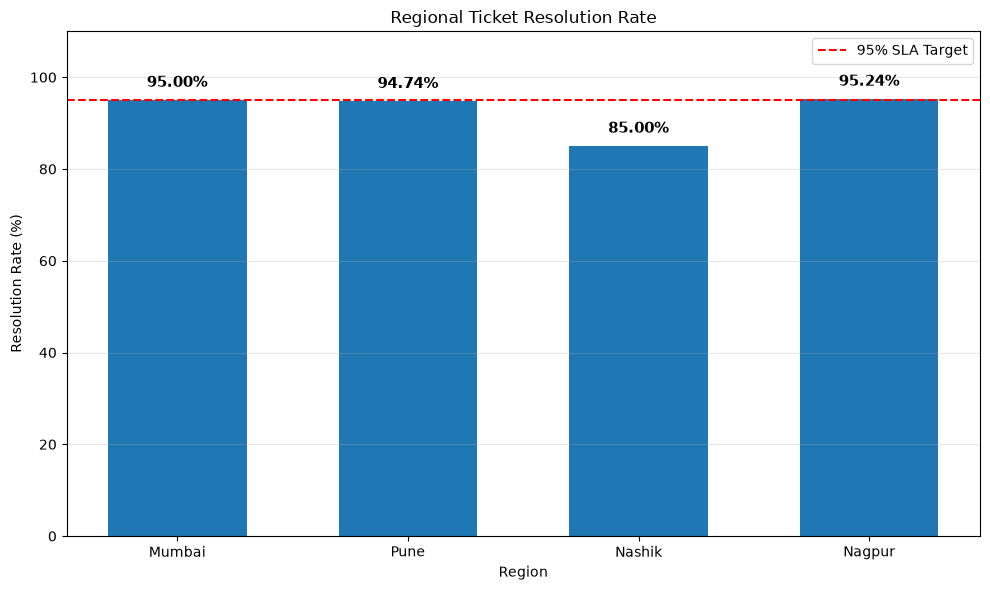

In [5]:


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    df["Region"],
    df["Resolution_Rate"],
    width=0.6
)

plt.axhline(y=95, color="red", linestyle="--",
            label="95% SLA Target")

for bar in bars:
    height = bar.get_height()
    plt.annotate(
        f"{height:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Regional Ticket Resolution Rate")
plt.xlabel("Region")
plt.ylabel("Resolution Rate (%)")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

import sqlite3
import pandas as pd

conn = sqlite3.connect(":memory:")

df.to_sql("regional_sla", conn, index=False, if_exists="replace")

query = """
SELECT
    Region,
    Total_Tickets,
    Resolved_Tickets,
    ROUND(100.0 * Resolved_Tickets / Total_Tickets, 2)
        AS Resolution_Rate,
    SLA_Target,
    CASE
        WHEN 100.0 * Resolved_Tickets / Total_Tickets >= SLA_Target
        THEN 'Met'
        ELSE 'Breached'
    END AS SLA_Status
FROM regional_sla
ORDER BY Resolution_Rate ASC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,Region,Total_Tickets,Resolved_Tickets,Resolution_Rate,SLA_Target,SLA_Status
0,Nashik,80,68,85.00,90,Breached
1,Pune,95,90,94.74,95,Breached
2,Mumbai,120,114,95.00,95,Met
3,Nagpur,105,100,95.24,95,Met


In [7]:

query = """
SELECT
    Region,
    SLA_Target,
    ROUND(
        100.0 * Resolved_Tickets / Total_Tickets, 2
    ) AS Resolution_Rate,
    ROUND(
        SLA_Target -
        (100.0 * Resolved_Tickets / Total_Tickets), 2
    ) AS SLA_Gap
FROM regional_sla
ORDER BY SLA_Gap DESC;
"""

gap_analysis = pd.read_sql_query(query, conn)
display(gap_analysis)


,Region,SLA_Target,Resolution_Rate,SLA_Gap
0,Nashik,90,85.00,5.00
1,Pune,95,94.74,0.26
2,Mumbai,95,95.00,0.00
3,Nagpur,95,95.24,-0.24


In [8]:

df.to_csv("telecom_sla_data.csv", index=False)

print("CSV dataset exported successfully!")


CSV dataset exported successfully!


In [9]:

sql_query = """
SELECT
    Region,
    Total_Tickets,
    Resolved_Tickets,
    ROUND(100.0 * Resolved_Tickets / Total_Tickets, 2)
        AS Resolution_Rate,
    SLA_Target,
    CASE
        WHEN 100.0 * Resolved_Tickets / Total_Tickets >= SLA_Target
        THEN 'Met'
        ELSE 'Breached'
    END AS SLA_Status
FROM regional_sla
ORDER BY Resolution_Rate ASC;
"""

with open("telecom_sla_analysis.sql", "w", encoding="utf-8") as file:
    file.write(sql_query)

print("SQL file exported successfully!")


SQL file exported successfully!


In [10]:

readme = """# Telecom Network SLA & Outage Intelligence

## Project Overview
This project analyses regional ticket resolution performance
against defined Service Level Agreement (SLA) targets.

## Objectives
- Calculate regional ticket resolution rates.
- Identify regions breaching their SLA targets.
- Quantify the gap between actual performance and target.
- Highlight regions requiring operational investigation.

## Tools Used
- Python
- Pandas
- Matplotlib
- SQL (SQLite)

## Key Findings
- Total tickets: 400
- Resolved tickets: 372
- Overall resolution rate: 93.00%
- Regions breaching SLA: 2
- Highest SLA gap: Nashik, at 5.00 percentage points below target.

## Files
- telecom_sla_data.csv: Sample dataset
- telecom_sla_analysis.sql: SQL analysis query
- telecom_sla_analysis.ipynb: Python analysis and visualisation

## Important Note
This project uses synthetic sample data for learning and demonstration.
It does not contain actual customer or company data.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")


README.md created successfully!
